In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.config('spark.ui.showConsoleProgress', 'false').appName("MobileMoneyAnalytics").getOrCreate()

df = spark.read.csv("synthetic_mobile_money_transaction_dataset.csv", header=True, inferSchema=True)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/abijedidiah/spark_easter_2026/venv/lib64/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/25 08:16:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
df.select("step", "amount", "oldBalInitiator", "newBalInitiator", "oldBalRecipient", "newBalRecipient", "isFraud").summary().show()

26/10/25 08:16:20 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-----------------+-----------------+------------------+------------------+------------------+------------------+-------------------+
|summary|             step|           amount|   oldBalInitiator|   newBalInitiator|   oldBalRecipient|   newBalRecipient|            isFraud|
+-------+-----------------+-----------------+------------------+------------------+------------------+------------------+-------------------+
|  count|          1720181|          1720181|           1720181|           1720181|           1720181|           1720181|            1720181|
|   mean|65.55528633324052|52538.67961221407|2433757.5979887336| 2443879.729006263|108508.32875252637|122277.21539521699|0.10203461147402512|
| stddev|44.67368440383682|88356.49798304687| 1307614.874018482|1297180.5297536347| 283013.7710270087| 319227.6798905368| 0.3026939094189067|
|    min|                0|             0.24|        -199997.11|        -199997.11|        -198368.47|        -135727.98|                  0|
|    2

In [3]:
df.groupBy("transactionType").count().orderBy("count", ascending=False).show()

+---------------+------+
|transactionType| count|
+---------------+------+
|        PAYMENT|667245|
|       TRANSFER|569328|
|        DEPOSIT|384431|
|     WITHDRAWAL| 93785|
|          DEBIT|  5392|
+---------------+------+



In [4]:
df.groupBy("isFraud").count().orderBy("isFraud").show()

+-------+-------+
|isFraud|  count|
+-------+-------+
|      0|1544663|
|      1| 175518|
+-------+-------+



In [5]:
from pyspark.sql.functions import min, max

df.select(min("step").alias("first_step"), max("step").alias("last_step")).show()

+----------+---------+
|first_step|last_step|
+----------+---------+
|         0|      143|
+----------+---------+



In [6]:
print("Unique initiators:", df.select("initiator").distinct().count())
print("Unique recipients:", df.select("recipient").distinct().count())

Unique initiators: 13462
Unique recipients: 16731


# Part 2: Behavioural features

In [7]:
from pyspark.sql.functions import col, floor, when

df = df.withColumn("hour", col("step") % 24)
df = df.withColumn("day", floor(col("step") / 24))
df = df.withColumn("is_night", when((col("hour") < 6) | (col("hour") >= 22), 1).otherwise(0))
df = df.withColumn("to_merchant", when(col("recipient").contains("-"), 1).otherwise(0))

In [8]:
df.select("step", "hour", "day", "is_night", "transactionType", "recipient", "to_merchant").show(10)

+----+----+---+--------+---------------+----------------+-----------+
|step|hour|day|is_night|transactionType|       recipient|to_merchant|
+----+----+---+--------+---------------+----------------+-----------+
|   0|   0|  0|       1|       TRANSFER|4875702729424478|          0|
|   0|   0|  0|       1|        PAYMENT|      25-0000401|          1|
|   0|   0|  0|       1|        PAYMENT|      13-0001587|          1|
|   0|   0|  0|       1|       TRANSFER|4096920916696293|          0|
|   0|   0|  0|       1|        PAYMENT|      75-0003564|          1|
|   0|   0|  0|       1|       TRANSFER|4593247015015219|          0|
|   0|   0|  0|       1|        PAYMENT|      11-0003866|          1|
|   0|   0|  0|       1|       TRANSFER|4649550475321678|          0|
|   0|   0|  0|       1|        PAYMENT|      64-0008405|          1|
|   0|   0|  0|       1|       TRANSFER|4863167876028593|          0|
+----+----+---+--------+---------------+----------------+-----------+
only showing top 10 

In [9]:
from pyspark.sql.functions import count, avg, sum

In [10]:
user_features = df.groupBy("initiator").agg(
    count("*").alias("tx_count"),
    avg("amount").alias("avg_amount"),
    sum("amount").alias("total_amount"),
    avg("is_night").alias("night_ratio"),
    sum("is_night").alias("night_tx"),
    avg(when(col("transactionType") == "DEPOSIT", 1).otherwise(0)).alias("cashin_ratio"),
    avg(when(col("transactionType") == "WITHDRAWAL", 1).otherwise(0)).alias("cashout_ratio"),
    avg("to_merchant").alias("agent_usage")
)

user_features.show(10)

+----------------+--------+------------------+--------------------+-------------------+--------+-------------------+--------------------+------------------+
|       initiator|tx_count|        avg_amount|        total_amount|        night_ratio|night_tx|       cashin_ratio|       cashout_ratio|       agent_usage|
+----------------+--------+------------------+--------------------+-------------------+--------+-------------------+--------------------+------------------+
|4946701648744458|       2| 597.2950000000001|  1194.5900000000001|                1.0|       2|                0.0|                 0.0|               1.0|
|4672051990792139|     100|108855.79809999999|1.0885579809999999E7|                0.2|      20|               0.46|                0.11|              0.87|
|4374674484354867|      53| 62731.36358490565|  3324762.2699999996|0.32075471698113206|      17|0.37735849056603776| 0.03773584905660377|0.7169811320754716|
|4794627091401754|      85| 20645.46352941176|  1754864.39

In [11]:
from pyspark.sql.functions import col

top10 = user_features.orderBy(col("tx_count").desc()).limit(10)
top10.select("initiator", "tx_count", "avg_amount", "total_amount", "night_ratio").show(10)

+----------------+--------+------------------+--------------------+-------------------+
|       initiator|tx_count|        avg_amount|        total_amount|        night_ratio|
+----------------+--------+------------------+--------------------+-------------------+
|4654047633050507|    1851| 54325.40372771476|1.0055632230000001E8| 0.2701242571582928|
|4703522567226712|    1814| 56112.76157111356|      1.0178854949E8|0.24807056229327454|
|4971664085133015|    1756|48455.640922551254| 8.508810546000001E7| 0.2744874715261959|
|4828576380583261|    1621|51470.691159777925| 8.343399037000002E7| 0.2689697717458359|
|4245745843396216|    1552| 60929.74214561857| 9.456295981000002E7|0.27384020618556704|
|4897326195323396|    1496| 50760.65032085561|       7.593793288E7|0.28810160427807485|
|4156998363881318|    1455|61767.231642611696| 8.987132204000002E7|0.24810996563573884|
|4945482194025615|    1429| 47555.28146256124| 6.795649721000001E7| 0.2722183344996501|
|4790092918847255|    1290| 4194

In [12]:
df.groupBy("transactionType").agg(
    count("*").alias("tx_count"),
    avg("amount").alias("avg_amount"),
    sum("amount").alias("total_amount")
).orderBy(col("tx_count").desc()).show()

+---------------+--------+-----------------+--------------------+
|transactionType|tx_count|       avg_amount|        total_amount|
+---------------+--------+-----------------+--------------------+
|        PAYMENT|  667245|1620.277218847673|1.0811218728900156E9|
|       TRANSFER|  569328|41798.18387642816|2.379687642999909E10|
|        DEPOSIT|  384431|138554.5477529132|5.326466334720017E10|
|     WITHDRAWAL|   93785|130042.8430007998|1.219606803083001E10|
|          DEBIT|    5392|6919.279135756677|        3.73087531E7|
+---------------+--------+-----------------+--------------------+



In [13]:
df.groupBy("to_merchant").agg(
    count("*").alias("tx_count"),
    avg("amount").alias("avg_amount")
).show()

+-----------+--------+-----------------+
|to_merchant|tx_count|       avg_amount|
+-----------+--------+-----------------+
|          1| 1150853|57852.01238039997|
|          0|  569328|41798.18387642816|
+-----------+--------+-----------------+



In [14]:
df.groupBy("day").agg(
    count("*").alias("tx_count"),
    sum("amount").alias("total_amount")
).orderBy("day").show()

+---+--------+--------------------+
|day|tx_count|        total_amount|
+---+--------+--------------------+
|  0|  435429|3.595457351898868...|
|  1|  364272|2.443554363012946...|
|  2|  196310|3.1996307848601966E9|
|  3|  208233| 4.793328411580027E9|
|  4|  202083|3.9220597323499084E9|
|  5|  313854|1.807090235610957...|
+---+--------+--------------------+



# Part 3: Behaviour Clustering

In [15]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, floor, when, count, avg, sum

spark = SparkSession.builder.appName("MobileMoneyClustering").getOrCreate()
df = spark.read.csv("synthetic_mobile_money_transaction_dataset.csv", header=True, inferSchema=True)

df = (df.withColumn("hour", col("step") % 24)
        .withColumn("day", floor(col("step") / 24))
        .withColumn("is_night", when((col("hour") < 6) | (col("hour") >= 22), 1).otherwise(0))
        .withColumn("to_merchant", when(col("recipient").contains("-"), 1).otherwise(0)))

user_features = df.groupBy("initiator").agg(
    count("*").alias("tx_count"),
    avg("amount").alias("avg_amount"),
    sum("amount").alias("total_amount"),
    avg("is_night").alias("night_ratio"),
    sum("is_night").alias("night_tx"),
    avg(when(col("transactionType") == "DEPOSIT", 1).otherwise(0)).alias("cashin_ratio"),
    avg(when(col("transactionType") == "WITHDRAWAL", 1).otherwise(0)).alias("cashout_ratio"),
    avg("to_merchant").alias("agent_usage")
)

26/10/25 08:16:41 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [16]:
from pyspark.ml.feature import VectorAssembler, StandardScaler

feature_cols = ["tx_count", "avg_amount", "cashin_ratio", "cashout_ratio", "night_tx", "agent_usage"]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features_raw")
data = assembler.transform(user_features)

scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True)
scaler_model = scaler.fit(data)
data = scaler_model.transform(data)

data.select("initiator", "features").show(5, truncate=False)

+----------------+--------------------------------------------------------------------------------------------------------------------------+
|initiator       |features                                                                                                                  |
+----------------+--------------------------------------------------------------------------------------------------------------------------+
|4946701648744458|[-0.7208545517152248,-1.2358919384963314,-1.0067106672547834,-0.6850101052814009,-0.6901116158186134,1.6894694929429313]  |
|4672051990792139|[-0.1592114523105541,1.4840244625699104,0.8373809896388998,1.4186165246020441,-0.3113947428017599,0.8551852692495893]     |
|4374674484354867|[-0.4285708979434064,0.32518148640547323,0.5060798634209207,0.036645685416178804,-0.3745142216379021,-0.12682417257232717]|
|4794627091401754|[-0.2451772328316772,-0.7321962394701074,-0.6294029113686078,-0.6850101052814009,-0.14307613257204724,-0.9530597223753461]|
|49049

In [17]:
user_features.count()

13462

In [18]:
from pyspark.ml.clustering import KMeans

kmeans = KMeans(k=4, seed=42, featuresCol="features", predictionCol="prediction")
km_model = kmeans.fit(data)
clusters = km_model.transform(data)

clusters.groupBy("prediction").count().orderBy("prediction").show()

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


+----------+-----+
|prediction|count|
+----------+-----+
|         0| 6665|
|         1| 3098|
|         2| 1800|
|         3| 1899|
+----------+-----+



In [19]:
from pyspark.ml.evaluation import ClusteringEvaluator

evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="prediction", metricName="silhouette")

ks, costs, sils = [], [], []
for k in range(2, 9):
    model = KMeans(k=k, seed=42, featuresCol="features").fit(data)
    preds = model.transform(data)
    ks.append(k)
    costs.append(model.summary.trainingCost)
    sils.append(evaluator.evaluate(preds))

for k, c, s in zip(ks, costs, sils):
    print(f"k={k}   cost={c:12.1f}   silhouette={s:.4f}")

k=2   cost=     59202.0   silhouette=0.4909
k=3   cost=     41088.7   silhouette=0.5125
k=4   cost=     31337.7   silhouette=0.5386
k=5   cost=     24296.6   silhouette=0.5517
k=6   cost=     20132.6   silhouette=0.5360
k=7   cost=     16825.5   silhouette=0.5569
k=8   cost=     15120.9   silhouette=0.5751


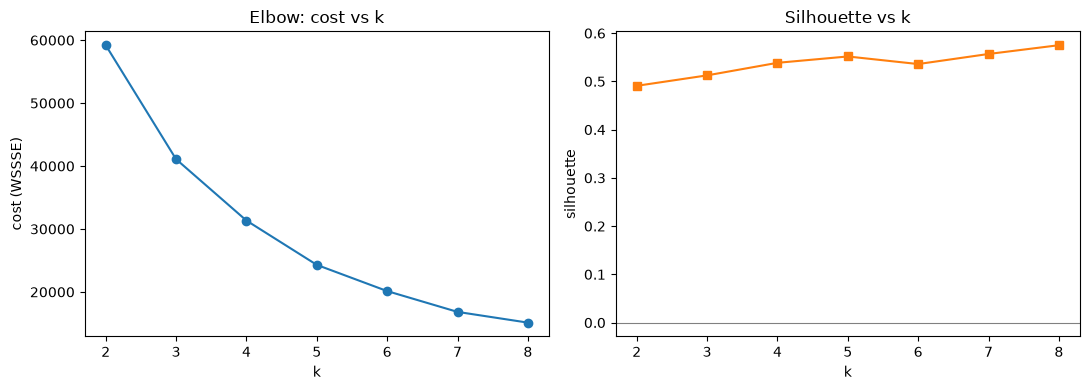

In [20]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(ks, costs, "o-", color="tab:blue")
ax1.set_title("Elbow: cost vs k")
ax1.set_xlabel("k")
ax1.set_ylabel("cost (WSSSE)")

ax2.plot(ks, sils, "s-", color="tab:orange")
ax2.set_title("Silhouette vs k")
ax2.set_xlabel("k")
ax2.set_ylabel("silhouette")
ax2.axhline(0, color="grey", lw=0.8)

plt.tight_layout()
plt.show()

In [21]:
from pyspark.sql.functions import round as sround

kmeans5 = KMeans(k=5, seed=42, featuresCol="features", predictionCol="prediction")
km5 = kmeans5.fit(data)
clusters = km5.transform(data)

profiles = (clusters.select("initiator", "prediction")
             .join(user_features, "initiator")
             .groupBy("prediction")
             .agg(
                 count("*").alias("wallets"),
                 sround(avg("tx_count"), 1).alias("tx_count"),
                 sround(avg("avg_amount"), 0).alias("avg_amount"),
                 sround(avg("total_amount"), 0).alias("total_amount"),
                 sround(avg("night_ratio"), 2).alias("night_ratio"),
                 sround(avg("cashin_ratio"), 2).alias("cashin_ratio"),
                 sround(avg("cashout_ratio"), 2).alias("cashout_ratio"),
                 sround(avg("agent_usage"), 2).alias("agent_usage")
             ).orderBy("prediction"))

profiles.show(truncate=False)

+----------+-------+--------+----------+------------+-----------+------------+-------------+-----------+
|prediction|wallets|tx_count|avg_amount|total_amount|night_ratio|cashin_ratio|cashout_ratio|agent_usage|
+----------+-------+--------+----------+------------+-----------+------------+-------------+-----------+
|0         |4960   |76.4    |30312.0   |2748420.0   |0.42       |0.14        |0.01         |0.61       |
|1         |1744   |22.5    |117302.0  |2488577.0   |0.2        |0.76        |0.03         |0.92       |
|2         |1566   |513.4   |49810.0   |2.6041133E7 |0.28       |0.19        |0.06         |0.65       |
|3         |3372   |143.2   |69779.0   |9371396.0   |0.25       |0.32        |0.09         |0.74       |
|4         |1820   |8.1     |1117.0    |12655.0     |0.79       |0.0         |0.0          |0.99       |
+----------+-------+--------+----------+------------+-----------+------------+-------------+-----------+



netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


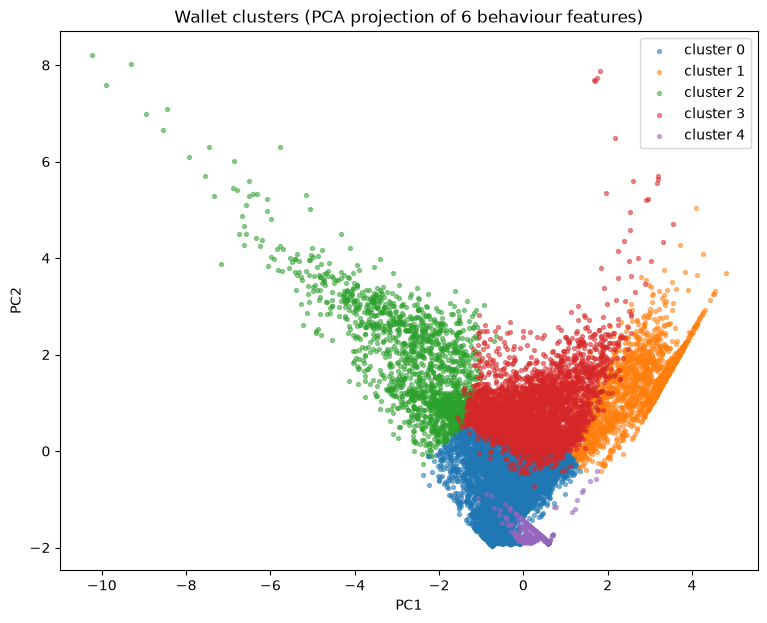

In [22]:
from pyspark.ml.feature import PCA

pca = PCA(k=2, inputCol="features", outputCol="pca_features")
pca_model = pca.fit(data)
pca_data = pca_model.transform(clusters)

points = pca_data.select("pca_features", "prediction").collect()

import matplotlib.pyplot as plt

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]
plt.figure(figsize=(9, 7))
for c in range(5):
    xs = [r.pca_features[0] for r in points if r.prediction == c]
    ys = [r.pca_features[1] for r in points if r.prediction == c]
    plt.scatter(xs, ys, s=8, alpha=0.5, color=colors[c], label=f"cluster {c}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Wallet clusters (PCA projection of 6 behaviour features)")
plt.legend()
plt.show()

In [23]:
from pyspark.ml.clustering import GaussianMixture

gm = GaussianMixture(k=5, seed=42, featuresCol="features", predictionCol="gm_prediction")
gm_model = gm.fit(data)
gm_result = gm_model.transform(data)

gm_result.groupBy("gm_prediction").count().orderBy("gm_prediction").show()

+-------------+-----+
|gm_prediction|count|
+-------------+-----+
|            0|  896|
|            1| 3861|
|            2| 2775|
|            3| 2552|
|            4| 3378|
+-------------+-----+



In [24]:
gm_result.select("initiator", "gm_prediction", "probability").show(5, truncate=70)

+----------------+-------------+----------------------------------------------------------------------+
|       initiator|gm_prediction|                                                           probability|
+----------------+-------------+----------------------------------------------------------------------+
|4946701648744458|            4|[7.111303228395028E-10,1.4454670529806864E-18,1.4454670529806864E-1...|
|4672051990792139|            3|[0.06781160690823637,2.9202077053285943E-8,6.799156632155221E-6,0.9...|
|4374674484354867|            2|[8.70099264572915E-4,3.896113984272069E-5,0.816047275136154,0.18304...|
|4794627091401754|            3|[6.844443395143361E-5,0.002428673473027914,0.03325743534073153,0.96...|
|4904906834372507|            1|[7.001459767014138E-16,0.9999998262072313,7.001459767014138E-16,1.7...|
+----------------+-------------+----------------------------------------------------------------------+
only showing top 5 rows


In [25]:
ct = (clusters.select("initiator", "prediction")
      .join(gm_result.select("initiator", "gm_prediction"), "initiator")
      .stat.crosstab("prediction", "gm_prediction"))
ct.show()

+------------------------+---+----+----+----+----+
|prediction_gm_prediction|  0|   1|   2|   3|   4|
+------------------------+---+----+----+----+----+
|                       3|349| 949| 306|1768|   0|
|                       0| 92|1356|1231| 713|1568|
|                       1|444|   0|1238|  62|   0|
|                       4| 10|   0|   0|   0|1810|
|                       2|  1|1556|   0|   9|   0|
+------------------------+---+----+----+----+----+

